<a href="https://colab.research.google.com/github/almudenaandradesoto/almudenaandradesoto-DataScience-GenAI-Submissions/blob/main/Seminar_Tasks/Week_07_Exploratory_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=1xqQczl0FG-qtNA2_WQYuWePW9oU8irqJ)

# 2.05 Exploratory Data Analysis (EDA)
In this exercise, you will explore a salary dataset (`EDA-DP.csv`) from the Week 7 Seminar Resources on myWBS. Work through the tasks in order. The setup cell below imports the libraries and allows you to upload the dataset.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from google.colab import files
upload = files.upload()

Saving EDA-DP.csv to EDA-DP.csv


**Task 1 — Load the data.** Read `EDA-DP.csv` into a pandas DataFrame and display the first few rows.

In [2]:
df_salary = pd.read_csv('EDA-DP.csv')
df_salary.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2024,SE,FT,AI Engineer,202730,USD,202730,US,0,US,M
1,2024,SE,FT,AI Engineer,92118,USD,92118,US,0,US,M
2,2024,SE,FT,Data Engineer,130500,USD,130500,US,0,US,M
3,2024,SE,FT,Data Engineer,96000,USD,96000,US,0,US,M
4,2024,SE,FT,Machine Learning Engineer,190000,USD,190000,US,0,US,M


**Task 2 — Dataset size.** Find the number of rows and columns in the dataset.

In [3]:
df_salary.shape

(16534, 11)

**Task 3 — Dataset structure.** Inspect the column names, data types, and number of non-missing values.

In [4]:
df_salary.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16534 entries, 0 to 16533
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           16534 non-null  int64 
 1   experience_level    16534 non-null  object
 2   employment_type     16534 non-null  object
 3   job_title           16534 non-null  object
 4   salary              16534 non-null  int64 
 5   salary_currency     16534 non-null  object
 6   salary_in_usd       16534 non-null  int64 
 7   employee_residence  16534 non-null  object
 8   remote_ratio        16534 non-null  int64 
 9   company_location    16534 non-null  object
 10  company_size        16534 non-null  object
dtypes: int64(4), object(7)
memory usage: 1.4+ MB


**Task 4 — Missing data.** Check how many missing values there are in each column.

In [5]:
df_salary.isnull().sum()

,0
work_year,0
experience_level,0
employment_type,0
job_title,0
salary,0
salary_currency,0
salary_in_usd,0
employee_residence,0
remote_ratio,0
company_location,0


**Task 5 — Missing-data percentages.** Calculate the percentage of missing values for each column. Think about how you would handle missing data if you found any.

In [7]:
# Percent of data which is not available
df_salary.isnull().sum()/len(df_salary) * 100

,0
work_year,0.0
experience_level,0.0
employment_type,0.0
job_title,0.0
salary,0.0
salary_currency,0.0
salary_in_usd,0.0
employee_residence,0.0
remote_ratio,0.0
company_location,0.0


There are no missing values in the dataset, so no action is needed. If there were missing values, I could either remove the affected rows or fill them using appropriate methods, such as the mean or median for numerical variables, depending on the amount and nature of the missing data.

**Task 6 — Duplicates.** Find how many rows are exact duplicates and how many are not. Would identical records necessarily be errors in this dataset?

In [8]:
df_salary.duplicated().value_counts()

,count
False,10113
True,6421


The dataset contains 6,421 duplicate rows and 10,113 non-duplicate rows. However, identical records are not necessarily errors, since different employees could have the same job title, salary, experience level, and other characteristics. Therefore, I would investigate the duplicates before deciding whether to remove them.

**Task 7 — Summary statistics.** Produce descriptive statistics for the numerical columns. What do the distributions tell you? Note that `salary` may use different currencies, whereas `salary_in_usd` is comparable across records.

In [9]:
df_salary.describe()

,work_year,salary,salary_in_usd,remote_ratio
count,16534.000000,1.653400e+04,16534.000000,16534.000000
mean,2023.226866,1.637270e+05,149686.777973,32.003750
std,0.713558,3.402057e+05,68505.293156,46.245158
min,2020.000000,1.400000e+04,15000.000000,0.000000
25%,2023.000000,1.017630e+05,101125.000000,0.000000
50%,2023.000000,1.422000e+05,141300.000000,0.000000
75%,2024.000000,1.872000e+05,185900.000000,100.000000
max,2024.000000,3.040000e+07,800000.000000,100.000000


The average salary in USD is approximately $149,687, while the median is $141,300. Since the mean is higher than the median, this suggests that the salary distribution is positively skewed. There are also some very high salaries, with a maximum of $800,000, which may be outliers. Most observations are from 2023 and 2024.

### Visualising the Data

**Task 8 — Bar chart.** Create a bar chart comparing the **average salary in USD** across experience levels (`EN`, `MI`, `SE`, `EX`). Add clear axis labels and a title. Which group has the highest average?

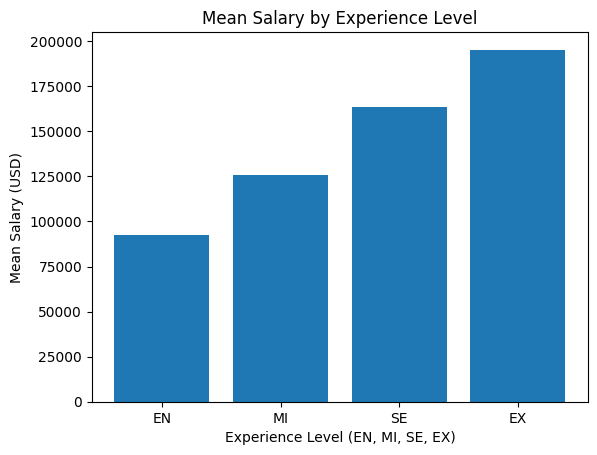

In [10]:
mean_salary_by_experience = df_salary.groupby('experience_level')['salary_in_usd'].mean().reindex(['EN', 'MI', 'SE', 'EX'])
#plt.bar() is a function from Matplotlib that creates a bar chart.
plt.bar(mean_salary_by_experience.index, mean_salary_by_experience.values)
plt.xlabel('Experience Level (EN, MI, SE, EX)')
plt.ylabel('Mean Salary (USD)')
plt.title('Mean Salary by Experience Level')
plt.show()


Executive-level (EX) employees have the highest average salary, followed by Senior-level (SE), Mid-level (MI), and Entry-level (EN) employees. This suggests a positive relationship between experience level and average salary.

**Task 9 — Scatter plot.** Make a scatter plot of `work_year` against `salary_in_usd`. Label the axes. What patterns do you notice? Are any points difficult to distinguish because they overlap?

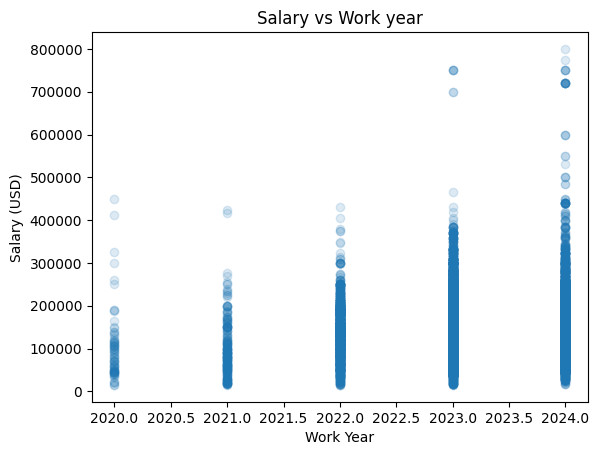

In [13]:
plt.scatter(df_salary['work_year'], df_salary['salary_in_usd'], alpha=0.15)
plt.xlabel('Work Year')
plt.ylabel('Salary (USD)')
plt.title('Salary vs Work year')
plt.show()

The scatter plot suggests that higher salaries are more common in recent years, particularly in 2023 and 2024. There are also some unusually high salaries. Many points overlap because the dataset contains a large number of observations for each year, making individual points difficult to distinguish.

**Task 10 — Distribution.** Plot the distribution of `salary_in_usd`. Does it look approximately normal, skewed, or something else? Are there extreme values?

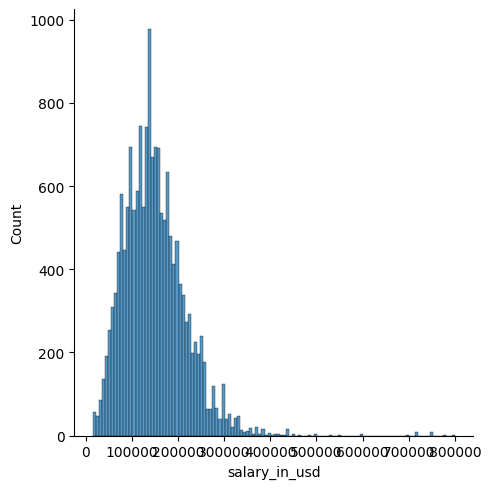

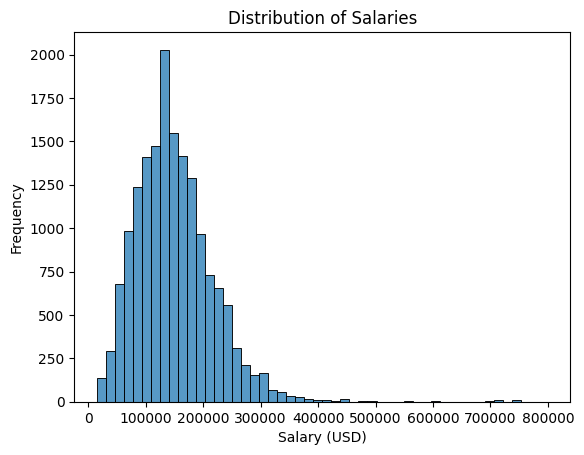

In [22]:
#First histogram
ax = sns.displot(df_salary['salary_in_usd'])


#Improved histogram
plt.figure()
sns.histplot(df_salary['salary_in_usd'], bins=50)
plt.xlabel('Salary (USD)')
plt.ylabel('Frequency')
plt.title('Distribution of Salaries')
plt.show()

The salary distribution is positively skewed (right-skewed), rather than normally distributed. Most salaries are concentrated between approximately $50,000 and $250,000, while a smaller number of observations have much higher salaries. These extreme values create a long right tail.

**Task 11 — Pairwise relationships.** Visualize pairwise relationships among `salary_in_usd`, `work_year`, and `remote_ratio`, including distributions of the individual variables.

Try to compare the variables in one combined visualization. What relationships or patterns do you notice?

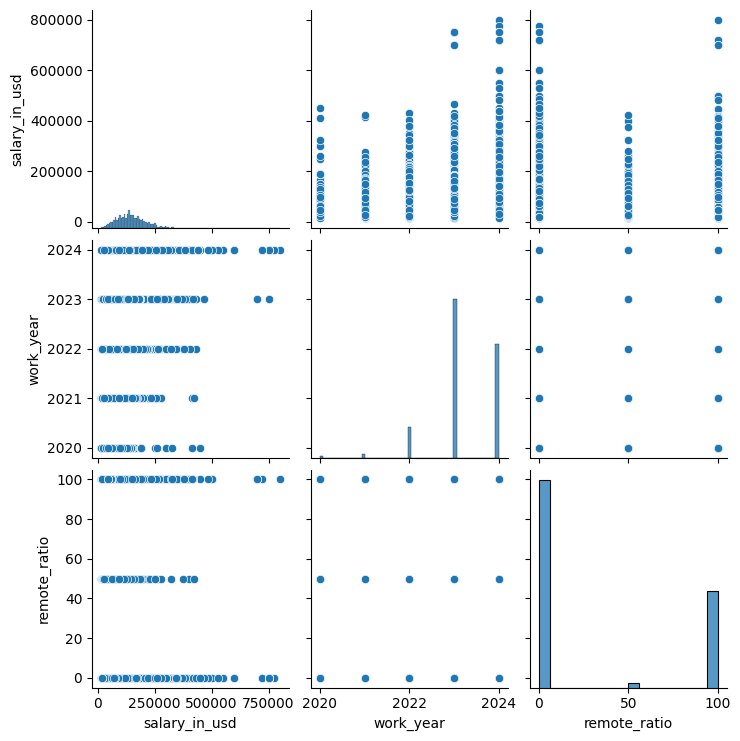

In [15]:
sns.pairplot(data = df_salary[['salary_in_usd','work_year','remote_ratio']],diag_kind='hist')

The pairplot shows that salary distributions are right-skewed, with a few extreme values. Higher salaries appear more frequently in recent years, especially 2023 and 2024. The remote ratio takes three values (0, 50, and 100), with most observations concentrated at 0 and 100. There is no clear relationship between remote work and salary from these plots alone.

**Task 12 — Remove a column.** Remove the original-currency `salary` column while retaining `salary_in_usd`, then inspect the updated DataFrame. Why might you choose to keep one salary column rather than both?

In [16]:
df_salary = df_salary.drop(['salary'], axis=1)
df_salary.head()

,work_year,experience_level,employment_type,job_title,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2024,SE,FT,AI Engineer,USD,202730,US,0,US,M
1,2024,SE,FT,AI Engineer,USD,92118,US,0,US,M
2,2024,SE,FT,Data Engineer,USD,130500,US,0,US,M
3,2024,SE,FT,Data Engineer,USD,96000,US,0,US,M
4,2024,SE,FT,Machine Learning Engineer,USD,190000,US,0,US,M


I would keep salary_in_usd because it allows salaries to be compared using the same currency. The original salary column contains values in different currencies, which makes direct comparisons difficult. Keeping only salary_in_usd also avoids having two variables representing essentially the same information.

**Reflection.** What have you learned about the salary dataset? Which additional checks or visualizations would be useful before building a machine learning model?

Well done!

 I learned that the dataset contains 16,534 observations with no missing values, although there are many duplicate records that should be investigated. Salaries are positively skewed, with some extreme values, and average salaries increase with experience level. Higher salaries also appear more frequently in recent years.

Before building a machine learning model, it would be useful to investigate the duplicate records and outliers, explore correlations between numerical variables, and compare salaries across job titles, company sizes, and locations. I would also consider transforming the salary variable to reduce skewness and encoding categorical variables so they can be used in the model.